# 02 — Correlation and Feature Selection
Explore associations between the target and candidate predictors. Correlation is descriptive, not proof of predictive value. The target is shifted by one month when comparing with predictors so the analysis is aligned with a one-month-ahead forecast.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

In [2]:
excluded = {
    TARGET, "Selected target source", "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV", "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV", "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
predictors = [c for c in df.select_dtypes(include=np.number).columns if c not in excluded]
# Use predictors observed at t to relate to target at t+1.
aligned = df[predictors].join(df[TARGET].shift(-1).rename("Target next month"))
# Correlations are calculated pairwise; no global complete-case deletion.
corr = aligned.corr(numeric_only=True)["Target next month"].drop("Target next month").dropna()
corr_table = corr.rename("Correlation with next-month target").to_frame()
corr_table["Absolute correlation"] = corr_table.iloc[:,0].abs()
display(corr_table.sort_values("Absolute correlation", ascending=False).head(20))

,Correlation with next-month target,Absolute correlation
LME lithium hydroxide price (USD/metric tonne),0.904326,0.904326
Albemarle share price (USD/share),0.826980,0.826980
SQM share price (USD/ADR),0.808427,0.808427
LME nickel price (USD/metric tonne),0.794102,0.794102
Japan lithium battery inventory (thousands),0.731348,0.731348
"Japan, Inventory - Lithium Batteries",0.619242,0.619242
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",0.575093,0.575093
LME cobalt cash price (USD/metric tonne) - updated Datastream,0.520258,0.520258
"China, Lithium Ion Battery Production",0.515940,0.515940
CNY/USD exchange-rate series (source quote),-0.291093,0.291093


## Japan index: specific comparison

In [3]:
if JAPAN_INDEX in corr_table.index:
    print(corr_table.loc[[JAPAN_INDEX]])
else:
    print("Japan import-price index not found in candidate predictors.")

                                                    Correlation with next-month target  Absolute correlation
Japan, Import Prices, Yen Basis, Lithium Carbon...                            0.575093              0.575093


## Correlation heatmap for leading variables
Use this only as an exploratory diagnostic. Highly correlated predictors can be redundant, and selecting variables based only on full-sample correlations can leak test-period information. Final feature selection should be made using training data only.

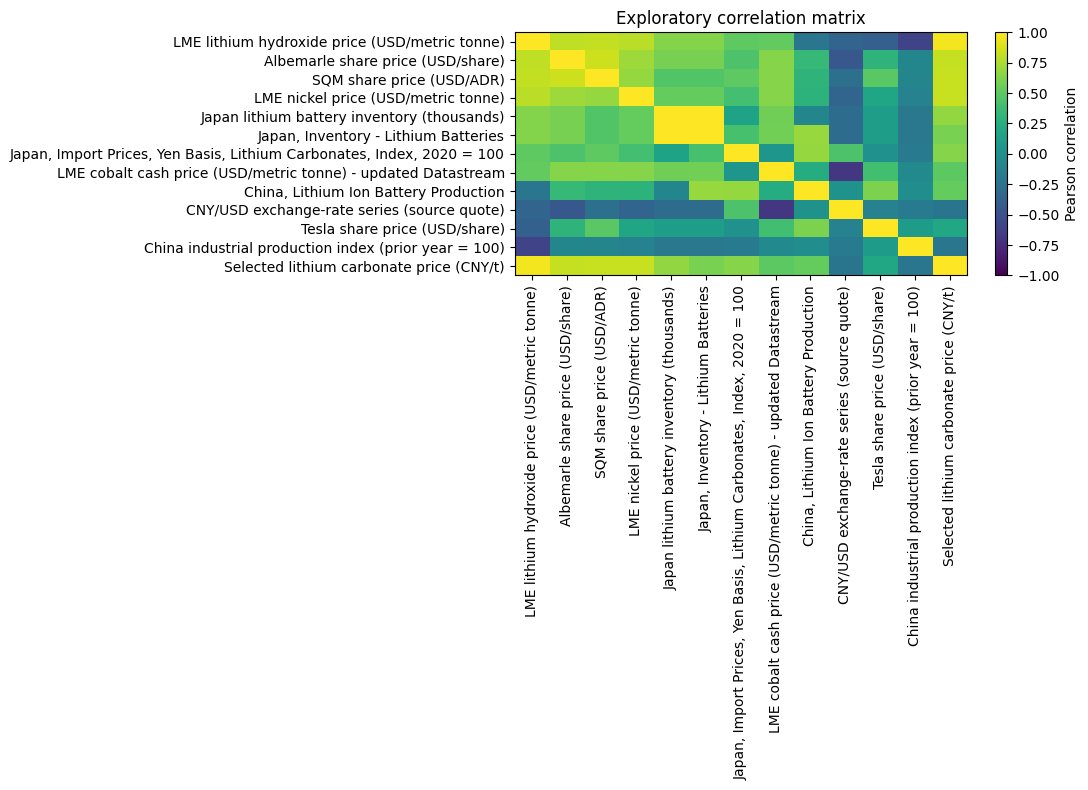

In [4]:
top = corr_table["Absolute correlation"].sort_values(ascending=False).head(12).index.tolist()
cols = top + [TARGET]
plot_df = df[cols].copy()
corr_mat = plot_df.corr()
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(corr_mat, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Exploratory correlation matrix")
plt.tight_layout()
plt.show()

## Recommendation for modeling
Keep the Japan index as an optional multivariate predictor. Compare:
1. Univariate target-lag model.
2. Multivariate model without Japan index.
3. Multivariate model with Japan index.

This tests whether it adds forecast information without changing the target definition.

In [5]:
corr_table.sort_values("Absolute correlation", ascending=False).to_csv("../results/next_month_predictor_correlations.csv")
print("Saved ../results/next_month_predictor_correlations.csv")

Saved ../results/next_month_predictor_correlations.csv
